**Cell 1: Instalasi CRF**

In [ ]:
# Library CRF untuk model sequence labeling
%pip install -q pytorch-crf==0.7.2

print("✓ Cell 1 berhasil: pytorch-crf sudah terpasang.")

✓ Cell 1 berhasil: pytorch-crf sudah terpasang.


**Cell 2: Import library dan konfigurasi perangkat**

In [ ]:
import json
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from google.colab import drive
from torch.nn.utils.rnn import (
    pack_padded_sequence,
    pad_packed_sequence,
)
from torch.utils.data import DataLoader, Dataset
from torchcrf import CRF
from tqdm.auto import tqdm

drive.mount("/content/drive")

# Menjaga hasil eksperimen tetap konsisten
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch :", torch.__version__)
print("Device  :", DEVICE)

if DEVICE.type == "cpu":
    print("⚠ Aktifkan GPU melalui Runtime > Change runtime type.")

print("✓ Cell 2 berhasil dijalankan.")

Mounted at /content/drive
PyTorch : 2.11.0+cu128
Device  : cuda
✓ Cell 2 berhasil dijalankan.


**Cell 3: Path dan hyperparameter**

In [ ]:
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/BiLSTM-CRF"
)

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MAPPING_DIR = PROJECT_ROOT / "mappings"
MODEL_DIR = PROJECT_ROOT / "models" / "baseline"
EVALUATION_DIR = PROJECT_ROOT / "evaluation" / "baseline"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
EVALUATION_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_PATH = PROCESSED_DIR / "fathul_train.csv"
VALIDATION_PATH = (
    PROCESSED_DIR / "fathul_validation.csv"
)

CHAR2ID_PATH = MAPPING_DIR / "char2id.json"
LABEL2ID_PATH = MAPPING_DIR / "label2id.json"

BEST_MODEL_PATH = MODEL_DIR / "best_model.pt"
FINAL_CHECKPOINT_PATH = MODEL_DIR / "final_checkpoint.pt"
CONFIG_PATH = MODEL_DIR / "baseline_config.json"
HISTORY_PATH = MODEL_DIR / "training_history.csv"
CURVE_PATH = EVALUATION_DIR / "training_curve.png"

# Hyperparameter baseline
MAX_LEN = 300
BATCH_SIZE = 32
EMBEDDING_DIM = 128
HIDDEN_DIM = 256
NUM_LAYERS = 1
DROPOUT = 0.30
LEARNING_RATE = 1e-3
MAX_EPOCHS = 100
PATIENCE = 5
GRAD_CLIP = 1.0

required_files = [
    TRAIN_PATH,
    VALIDATION_PATH,
    CHAR2ID_PATH,
    LABEL2ID_PATH,
]

for file_path in required_files:
    if not file_path.exists():
        raise FileNotFoundError(
            f"File tidak ditemukan: {file_path}"
        )

print("Train data      :", TRAIN_PATH)
print("Validation data :", VALIDATION_PATH)
print("Model output    :", MODEL_DIR)
print("Batch size      :", BATCH_SIZE)
print("Maximum epoch   :", MAX_EPOCHS)
print("✓ Cell 3 berhasil dijalankan.")

Train data      : /content/drive/MyDrive/BiLSTM-CRF/data/processed/fathul_train.csv
Validation data : /content/drive/MyDrive/BiLSTM-CRF/data/processed/fathul_validation.csv
Model output    : /content/drive/MyDrive/BiLSTM-CRF/models/baseline
Batch size      : 32
Maximum epoch   : 30
✓ Cell 3 berhasil dijalankan.


**Cell 4: Memuat data dan mapping**

In [ ]:
train_data = pd.read_csv(
    TRAIN_PATH,
    encoding="utf-8-sig",
)

validation_data = pd.read_csv(
    VALIDATION_PATH,
    encoding="utf-8-sig",
)

with open(
    CHAR2ID_PATH,
    encoding="utf-8",
) as file:
    char2id = json.load(file)

with open(
    LABEL2ID_PATH,
    encoding="utf-8",
) as file:
    label2id = json.load(file)

id2char = {
    index: char
    for char, index in char2id.items()
}

id2label = {
    index: label
    for label, index in label2id.items()
}

required_columns = {
    "page",
    "chunk_id",
    "text_undiacritized",
    "text_diacritized",
    "length",
    "split",
}

assert required_columns.issubset(train_data.columns)
assert required_columns.issubset(validation_data.columns)

assert train_data["split"].eq("train").all()
assert validation_data["split"].eq("validation").all()

assert set(train_data["page"]).isdisjoint(
    set(validation_data["page"])
)

assert train_data["length"].between(1, MAX_LEN).all()
assert validation_data["length"].between(1, MAX_LEN).all()

assert len(label2id) == 15
assert "<PAD>" not in label2id
assert "<PAD>" in char2id
assert "<UNK>" in char2id
assert "O" in label2id

PAD_CHAR_ID = char2id["<PAD>"]
UNK_CHAR_ID = char2id["<UNK>"]
O_LABEL_ID = label2id["O"]

data_summary = pd.DataFrame([
    {
        "split": "train",
        "pages": train_data["page"].nunique(),
        "sequences": len(train_data),
        "characters": train_data["length"].sum(),
    },
    {
        "split": "validation",
        "pages": validation_data["page"].nunique(),
        "sequences": len(validation_data),
        "characters": validation_data["length"].sum(),
    },
])

display(data_summary)

print("Vocabulary size :", len(char2id))
print("Number of labels:", len(label2id))
print("PAD character ID:", PAD_CHAR_ID)
print("O label ID      :", O_LABEL_ID)
print("✓ Cell 4 berhasil dijalankan.")

,split,pages,sequences,characters
0,train,263,857,218732
1,validation,33,110,27933


Vocabulary size : 55
Number of labels: 15
PAD character ID: 0
O label ID      : 0
✓ Cell 4 berhasil dijalankan.


**Cell 5: Validasi karakter dan label**

In [ ]:
from collections import Counter

HARAKAT = set("ًٌٍَُِّْ")


def extract_chars_and_labels(text):
    chars = []
    labels = []
    index = 0

    while index < len(text):
        char = text[index]

        if char in HARAKAT:
            raise ValueError(
                f"Harakat tanpa karakter dasar pada indeks {index}."
            )

        chars.append(char)
        marks = []
        next_index = index + 1

        while (
            next_index < len(text)
            and text[next_index] in HARAKAT
        ):
            mark = text[next_index]

            if mark not in marks:
                marks.append(mark)

            next_index += 1

        label = "|".join(marks) if marks else "O"

        if label not in label2id:
            raise ValueError(
                f"Label tidak tersedia: {repr(label)}"
            )

        labels.append(label)
        index = next_index

    return chars, labels


def validate_frame(frame):
    distribution = Counter()
    unknown_characters = Counter()

    for row in frame.itertuples(index=False):
        chars, labels = extract_chars_and_labels(
            row.text_diacritized
        )

        assert len(chars) == len(labels)
        assert "".join(chars) == row.text_undiacritized
        assert len(chars) == row.length

        distribution.update(labels)

        unknown_characters.update(
            char
            for char in chars
            if char not in char2id
        )

    return distribution, unknown_characters


train_distribution, train_unknown = validate_frame(
    train_data
)

validation_distribution, validation_unknown = (
    validate_frame(validation_data)
)

assert len(train_distribution) == 15
assert not train_unknown

distribution_table = pd.DataFrame({
    "label": list(label2id.keys()),
    "train": [
        train_distribution.get(label, 0)
        for label in label2id
    ],
    "validation": [
        validation_distribution.get(label, 0)
        for label in label2id
    ],
})

display(distribution_table)

print("Unknown train      :", dict(train_unknown))
print("Unknown validation :", dict(validation_unknown))
print("✓ Cell 5 berhasil dijalankan.")

,label,train,validation
0,O,85975,10947
1,َ,53961,6827
2,ُ,15739,2058
3,ِ,26972,3452
4,ْ,22930,3056
5,ً,1451,186
6,ٌ,1203,137
7,ٍ,2058,200
8,ّ,3,0
9,َ|ّ,5308,687


Unknown train      : {}
Unknown validation : {'/': 1, '٣': 2, '!': 1}
✓ Cell 5 berhasil dijalankan.


**Cell 6: Dataset PyTorch**

In [ ]:
class DiacritizationDataset(Dataset):
    def __init__(self, frame):
        self.samples = []

        for row in frame.itertuples(index=False):
            chars, labels = extract_chars_and_labels(
                row.text_diacritized
            )

            char_ids = [
                char2id.get(char, UNK_CHAR_ID)
                for char in chars
            ]

            label_ids = [
                label2id[label]
                for label in labels
            ]

            self.samples.append({
                "char_ids": char_ids,
                "label_ids": label_ids,
                "chars": chars,
                "labels": labels,
                "length": len(chars),
                "page": int(row.page),
                "chunk_id": row.chunk_id,
                "text_undiacritized": row.text_undiacritized,
                "text_diacritized": row.text_diacritized,
            })

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        return self.samples[index]


train_dataset = DiacritizationDataset(
    train_data
)

validation_dataset = DiacritizationDataset(
    validation_data
)

assert len(train_dataset) == len(train_data)
assert len(validation_dataset) == len(validation_data)

sample = train_dataset[0]

assert len(sample["char_ids"]) == sample["length"]
assert len(sample["label_ids"]) == sample["length"]

print("Train dataset      :", len(train_dataset))
print("Validation dataset :", len(validation_dataset))
print("Contoh chunk       :", sample["chunk_id"])
print("Panjang contoh     :", sample["length"])
print("✓ Cell 6 berhasil dijalankan.")

Train dataset      : 857
Validation dataset : 110
Contoh chunk       : FQ_020_01
Panjang contoh     : 297
✓ Cell 6 berhasil dijalankan.


**Cell 7: Dynamic padding dan DataLoader**

In [ ]:
def collate_batch(batch):
    lengths = [
        sample["length"]
        for sample in batch
    ]
    max_batch_length = max(lengths)

    char_batch = []
    label_batch = []
    mask_batch = []

    for sample in batch:
        padding_length = (
            max_batch_length - sample["length"]
        )

        char_batch.append(
            sample["char_ids"]
            + [PAD_CHAR_ID] * padding_length
        )

        label_batch.append(
            sample["label_ids"]
            + [O_LABEL_ID] * padding_length
        )

        mask_batch.append(
            [True] * sample["length"]
            + [False] * padding_length
        )

    return {
        "char_ids": torch.tensor(
            char_batch,
            dtype=torch.long,
        ),
        "label_ids": torch.tensor(
            label_batch,
            dtype=torch.long,
        ),
        "mask": torch.tensor(
            mask_batch,
            dtype=torch.bool,
        ),
        "lengths": torch.tensor(
            lengths,
            dtype=torch.long,
        ),
        "samples": batch,
    }


train_generator = torch.Generator()
train_generator.manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_batch,
    generator=train_generator,
    num_workers=0,
    pin_memory=DEVICE.type == "cuda",
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_batch,
    num_workers=0,
    pin_memory=DEVICE.type == "cuda",
)

sample_batch = next(iter(train_loader))

assert sample_batch["char_ids"].shape == (
    sample_batch["label_ids"].shape
)

assert sample_batch["char_ids"].shape == (
    sample_batch["mask"].shape
)

assert sample_batch["mask"][:, 0].all()

print("Jumlah batch train     :", len(train_loader))
print("Jumlah batch validation:", len(validation_loader))
print("Bentuk batch contoh    :", sample_batch["char_ids"].shape)
print("✓ Cell 7 berhasil dijalankan.")

Jumlah batch train     : 27
Jumlah batch validation: 4
Bentuk batch contoh    : torch.Size([32, 300])
✓ Cell 7 berhasil dijalankan.


**Cell 8: Model BiLSTM-CRF**

In [ ]:
class BiLSTMCRF(nn.Module):
    def __init__(
        self,
        vocab_size,
        num_labels,
        embedding_dim,
        hidden_dim,
        num_layers,
        dropout,
        pad_char_id,
    ):
        super().__init__()

        if hidden_dim % 2 != 0:
            raise ValueError(
                "Hidden dimension harus bernilai genap."
            )

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=pad_char_id,
        )

        self.embedding_dropout = nn.Dropout(dropout)

        self.bilstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim // 2,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
        )

        self.output_dropout = nn.Dropout(dropout)

        self.classifier = nn.Linear(
            hidden_dim,
            num_labels,
        )

        self.crf = CRF(
            num_tags=num_labels,
            batch_first=True,
        )

    def compute_emissions(
        self,
        char_ids,
        lengths,
    ):
        embedded = self.embedding(char_ids)
        embedded = self.embedding_dropout(embedded)

        packed = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False,
        )

        packed_output, _ = self.bilstm(packed)

        encoded, _ = pad_packed_sequence(
            packed_output,
            batch_first=True,
            total_length=char_ids.size(1),
        )

        encoded = self.output_dropout(encoded)
        return self.classifier(encoded)

    def loss(
        self,
        char_ids,
        label_ids,
        mask,
        lengths,
    ):
        emissions = self.compute_emissions(
            char_ids,
            lengths,
        )

        log_likelihood = self.crf(
            emissions,
            label_ids,
            mask=mask,
            reduction="token_mean",
        )

        return -log_likelihood

    def decode(
        self,
        char_ids,
        mask,
        lengths,
    ):
        emissions = self.compute_emissions(
            char_ids,
            lengths,
        )

        return self.crf.decode(
            emissions,
            mask=mask,
        )


model = BiLSTMCRF(
    vocab_size=len(char2id),
    num_labels=len(label2id),
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS,
    dropout=DROPOUT,
    pad_char_id=PAD_CHAR_ID,
).to(DEVICE)

trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

test_char_ids = sample_batch["char_ids"].to(DEVICE)
test_label_ids = sample_batch["label_ids"].to(DEVICE)
test_mask = sample_batch["mask"].to(DEVICE)
test_lengths = sample_batch["lengths"]

model.eval()

with torch.no_grad():
    test_loss = model.loss(
        test_char_ids,
        test_label_ids,
        test_mask,
        test_lengths,
    )

    test_predictions = model.decode(
        test_char_ids,
        test_mask,
        test_lengths,
    )

assert torch.isfinite(test_loss)
assert len(test_predictions) == len(test_lengths)

for prediction, length in zip(
    test_predictions,
    test_lengths,
):
    assert len(prediction) == int(length)

print("Trainable parameters:", f"{trainable_parameters:,}")
print("Initial batch loss  :", round(test_loss.item(), 4))
print("Prediction count    :", len(test_predictions))
print("✓ Cell 8 berhasil dijalankan.")

Trainable parameters: 275,342
Initial batch loss  : 2.711
Prediction count    : 32
✓ Cell 8 berhasil dijalankan.


**Cell 9: Fungsi training dan validation**

In [ ]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
)


def run_epoch(loader, training):
    if training:
        model.train()
        description = "Training"
    else:
        model.eval()
        description = "Validation"

    total_loss = 0.0
    total_tokens = 0

    progress_bar = tqdm(
        loader,
        desc=description,
        leave=False,
    )

    for batch in progress_bar:
        char_ids = batch["char_ids"].to(
            DEVICE,
            non_blocking=True,
        )
        label_ids = batch["label_ids"].to(
            DEVICE,
            non_blocking=True,
        )
        mask = batch["mask"].to(
            DEVICE,
            non_blocking=True,
        )
        lengths = batch["lengths"]

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            loss = model.loss(
                char_ids,
                label_ids,
                mask,
                lengths,
            )

            if training:
                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    GRAD_CLIP,
                )

                optimizer.step()

        valid_tokens = int(mask.sum().item())

        total_loss += loss.item() * valid_tokens
        total_tokens += valid_tokens

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    return total_loss / total_tokens


initial_validation_loss = run_epoch(
    validation_loader,
    training=False,
)

assert np.isfinite(initial_validation_loss)

print(
    "Initial validation loss:",
    round(initial_validation_loss, 4),
)
print("Optimizer              : Adam")
print("Learning rate          :", LEARNING_RATE)
print("✓ Cell 9 berhasil dijalankan.")

Validation:   0%|          | 0/4 [00:00<?, ?it/s]

Initial validation loss: 2.7117
Optimizer              : Adam
Learning rate          : 0.001
✓ Cell 9 berhasil dijalankan.


**Cell 10: Training loop dan early stopping**

In [ ]:
MIN_DELTA = 1e-4

history = []
best_validation_loss = float("inf")
best_epoch = 0
patience_counter = 0

training_started = time.time()

for epoch in range(1, MAX_EPOCHS + 1):
    epoch_started = time.time()

    train_loss = run_epoch(
        train_loader,
        training=True,
    )

    validation_loss = run_epoch(
        validation_loader,
        training=False,
    )

    epoch_duration = time.time() - epoch_started

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "validation_loss": validation_loss,
        "duration_seconds": epoch_duration,
    })

    history_df = pd.DataFrame(history)
    history_df.to_csv(
        HISTORY_PATH,
        index=False,
    )

    improved = (
        validation_loss
        < best_validation_loss - MIN_DELTA
    )

    if improved:
        best_validation_loss = validation_loss
        best_epoch = epoch
        patience_counter = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "train_loss": train_loss,
                "validation_loss": validation_loss,
                "char2id": char2id,
                "label2id": label2id,
            },
            BEST_MODEL_PATH,
        )

        status = "model terbaik disimpan"
    else:
        patience_counter += 1
        status = (
            f"patience {patience_counter}/{PATIENCE}"
        )

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"train {train_loss:.4f} | "
        f"val {validation_loss:.4f} | "
        f"{epoch_duration:.1f}s | {status}"
    )

    if patience_counter >= PATIENCE:
        print("Early stopping dijalankan.")
        break


total_training_time = time.time() - training_started

torch.save(
    {
        "last_epoch": history[-1]["epoch"],
        "best_epoch": best_epoch,
        "best_validation_loss": best_validation_loss,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "history": history,
    },
    FINAL_CHECKPOINT_PATH,
)

print("\nTraining selesai.")
print("Epoch terbaik       :", best_epoch)
print(
    "Validation loss terbaik:",
    round(best_validation_loss, 4),
)
print(
    "Total waktu training:",
    round(total_training_time / 60, 2),
    "menit",
)
print("Model terbaik       :", BEST_MODEL_PATH)
print("✓ Cell 10 berhasil dijalankan.")

Training:   0%|          | 0/27 [00:00<?, ?it/s]

Validation:   0%|          | 0/4 [00:00<?, ?it/s]

Epoch 01/30 | train 1.7026 | val 1.1348 | 12.7s | model terbaik disimpan


Training:   0%|          | 0/27 [00:00<?, ?it/s]

Validation:   0%|          | 0/4 [00:00<?, ?it/s]

Epoch 02/30 | train 1.0320 | val 0.8723 | 10.3s | model terbaik disimpan


... (80 outputs left out)

Epoch 29/30 | train 0.2564 | val 0.2450 | 11.0s | model terbaik disimpan


Training:   0%|          | 0/27 [00:00<?, ?it/s]

Validation:   0%|          | 0/4 [00:00<?, ?it/s]

Epoch 30/30 | train 0.2509 | val 0.2429 | 10.0s | model terbaik disimpan

Training selesai.
Epoch terbaik       : 30
Validation loss terbaik: 0.2429
Total waktu training: 5.51 menit
Model terbaik       : /content/drive/MyDrive/BiLSTM-CRF/models/baseline/best_model.pt
✓ Cell 10 berhasil dijalankan.


**Cell 10B — Melanjutkan training epoch 31–50,51-100**

In [ ]:
TARGET_EPOCHS = 100

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=DEVICE,
    weights_only=False,
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

optimizer.load_state_dict(
    checkpoint["optimizer_state_dict"]
)

history_df = pd.read_csv(HISTORY_PATH)
history = history_df.to_dict("records")

start_epoch = int(checkpoint["epoch"]) + 1
best_epoch = int(checkpoint["epoch"])
best_validation_loss = float(
    checkpoint["validation_loss"]
)
patience_counter = 0

continuation_started = time.time()

for epoch in range(start_epoch, TARGET_EPOCHS + 1):
    epoch_started = time.time()

    train_loss = run_epoch(
        train_loader,
        training=True,
    )

    validation_loss = run_epoch(
        validation_loader,
        training=False,
    )

    epoch_duration = time.time() - epoch_started

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "validation_loss": validation_loss,
        "duration_seconds": epoch_duration,
    })

    pd.DataFrame(history).to_csv(
        HISTORY_PATH,
        index=False,
    )

    improved = (
        validation_loss
        < best_validation_loss - MIN_DELTA
    )

    if improved:
        best_validation_loss = validation_loss
        best_epoch = epoch
        patience_counter = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "train_loss": train_loss,
                "validation_loss": validation_loss,
                "char2id": char2id,
                "label2id": label2id,
            },
            BEST_MODEL_PATH,
        )

        status = "model terbaik disimpan"
    else:
        patience_counter += 1
        status = (
            f"patience {patience_counter}/{PATIENCE}"
        )

    print(
        f"Epoch {epoch:02d}/{TARGET_EPOCHS} | "
        f"train {train_loss:.4f} | "
        f"val {validation_loss:.4f} | "
        f"{epoch_duration:.1f}s | {status}"
    )

    if patience_counter >= PATIENCE:
        print("Early stopping dijalankan.")
        break


torch.save(
    {
        "last_epoch": history[-1]["epoch"],
        "best_epoch": best_epoch,
        "best_validation_loss": best_validation_loss,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "history": history,
    },
    FINAL_CHECKPOINT_PATH,
)

continuation_time = time.time() - continuation_started

print("\nTraining lanjutan selesai.")
print("Epoch terbaik       :", best_epoch)
print(
    "Validation loss terbaik:",
    round(best_validation_loss, 4),
)
print(
    "Waktu tambahan      :",
    round(continuation_time / 60, 2),
    "menit",
)
print("✓ Cell 10B berhasil dijalankan.")

Training:   0%|          | 0/27 [00:00<?, ?it/s]

Validation:   0%|          | 0/4 [00:00<?, ?it/s]

Epoch 51/100 | train 0.1832 | val 0.2073 | 11.0s | patience 1/5


Training:   0%|          | 0/27 [00:00<?, ?it/s]

Validation:   0%|          | 0/4 [00:00<?, ?it/s]

Epoch 52/100 | train 0.1818 | val 0.2045 | 11.2s | model terbaik disimpan


... (89 outputs left out)

Epoch 82/100 | train 0.1335 | val 0.1931 | 11.0s | patience 4/5


Training:   0%|          | 0/27 [00:00<?, ?it/s]

Validation:   0%|          | 0/4 [00:00<?, ?it/s]

Epoch 83/100 | train 0.1328 | val 0.1945 | 10.9s | patience 5/5
Early stopping dijalankan.

Training lanjutan selesai.
Epoch terbaik       : 78
Validation loss terbaik: 0.1921
Waktu tambahan      : 5.98 menit
✓ Cell 10B berhasil dijalankan.


**Cell 11: Grafik training**

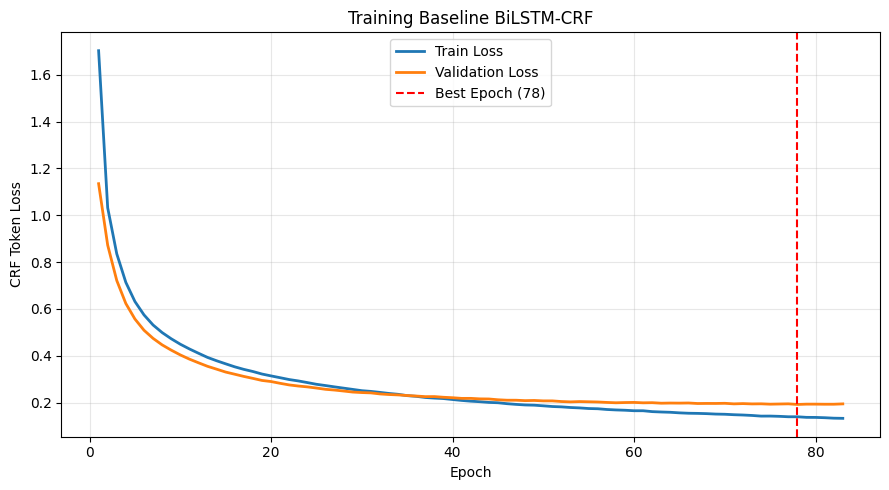

Epoch terbaik    : 78
Validation loss : 0.1921
Grafik tersimpan : /content/drive/MyDrive/BiLSTM-CRF/evaluation/baseline/training_curve.png
✓ Cell 11 berhasil dijalankan.


In [ ]:
history_df = pd.read_csv(HISTORY_PATH)

assert history_df["epoch"].is_unique
assert history_df["epoch"].min() == 1
assert history_df["epoch"].max() == 83

best_row = history_df.loc[
    history_df["validation_loss"].idxmin()
]

best_epoch_from_history = int(best_row["epoch"])
best_loss_from_history = float(
    best_row["validation_loss"]
)

assert best_epoch_from_history == 78

plt.figure(figsize=(9, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Train Loss",
    linewidth=2,
)

plt.plot(
    history_df["epoch"],
    history_df["validation_loss"],
    label="Validation Loss",
    linewidth=2,
)

plt.axvline(
    best_epoch_from_history,
    color="red",
    linestyle="--",
    label=f"Best Epoch ({best_epoch_from_history})",
)

plt.xlabel("Epoch")
plt.ylabel("CRF Token Loss")
plt.title("Training Baseline BiLSTM-CRF")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    CURVE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Epoch terbaik    :", best_epoch_from_history)
print(
    "Validation loss :",
    round(best_loss_from_history, 4),
)
print("Grafik tersimpan :", CURVE_PATH)
print("✓ Cell 11 berhasil dijalankan.")

**Cell 12: Memuat dan memvalidasi model terbaik**

In [ ]:
best_checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=DEVICE,
    weights_only=False,
)

assert best_checkpoint["epoch"] == 78
assert best_checkpoint["char2id"] == char2id
assert best_checkpoint["label2id"] == label2id

model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

model.to(DEVICE)
model.eval()

recalculated_validation_loss = run_epoch(
    validation_loader,
    training=False,
)

saved_validation_loss = float(
    best_checkpoint["validation_loss"]
)

assert abs(
    recalculated_validation_loss
    - saved_validation_loss
) < 1e-4

print("Checkpoint epoch        :", best_checkpoint["epoch"])
print(
    "Saved validation loss  :",
    round(saved_validation_loss, 4),
)
print(
    "Checked validation loss:",
    round(recalculated_validation_loss, 4),
)
print("Model terbaik berhasil dimuat.")
print("✓ Cell 12 berhasil dijalankan.")

Validation:   0%|          | 0/4 [00:00<?, ?it/s]

Checkpoint epoch        : 78
Saved validation loss  : 0.1921
Checked validation loss: 0.1921
Model terbaik berhasil dimuat.
✓ Cell 12 berhasil dijalankan.


**Cell 13: Menyimpan konfigurasi dan audit training**

In [ ]:
baseline_config = {
    "model_name": "BiLSTM-CRF Baseline",
    "dataset": "Fathul Qorib",
    "seed": SEED,
    "vocabulary_size": len(char2id),
    "number_of_labels": len(label2id),
    "max_sequence_length": MAX_LEN,
    "embedding_dimension": EMBEDDING_DIM,
    "hidden_dimension": HIDDEN_DIM,
    "number_of_lstm_layers": NUM_LAYERS,
    "dropout": DROPOUT,
    "batch_size": BATCH_SIZE,
    "optimizer": "Adam",
    "initial_learning_rate": LEARNING_RATE,
    "loss_reduction": "token_mean",
    "gradient_clip": GRAD_CLIP,
    "maximum_epochs": 100,
    "early_stopping_patience": PATIENCE,
    "minimum_improvement": MIN_DELTA,
    "completed_epochs": int(
        history_df["epoch"].max()
    ),
    "best_epoch": int(
        best_checkpoint["epoch"]
    ),
    "best_validation_loss": float(
        best_checkpoint["validation_loss"]
    ),
    "train_pages": int(
        train_data["page"].nunique()
    ),
    "train_sequences": int(len(train_data)),
    "validation_pages": int(
        validation_data["page"].nunique()
    ),
    "validation_sequences": int(
        len(validation_data)
    ),
    "uses_tashkeela": False,
    "uses_test_data": False,
}

with open(
    CONFIG_PATH,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        baseline_config,
        file,
        ensure_ascii=False,
        indent=2,
    )


required_outputs = [
    BEST_MODEL_PATH,
    FINAL_CHECKPOINT_PATH,
    CONFIG_PATH,
    HISTORY_PATH,
    CURVE_PATH,
]

for file_path in required_outputs:
    assert file_path.exists()
    assert file_path.stat().st_size > 0


training_audit = {
    "status": "passed",
    "best_model_loadable": True,
    "validation_loss_verified": True,
    "test_data_used": False,
    "tashkeela_used": False,
    "best_epoch": int(
        best_checkpoint["epoch"]
    ),
    "best_validation_loss": float(
        best_checkpoint["validation_loss"]
    ),
}

AUDIT_PATH = MODEL_DIR / "training_audit.json"

with open(
    AUDIT_PATH,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        training_audit,
        file,
        ensure_ascii=False,
        indent=2,
    )


print("Status audit          :", training_audit["status"])
print("Model                 : BiLSTM-CRF Baseline")
print("Epoch selesai         :", baseline_config["completed_epochs"])
print("Epoch terbaik         :", baseline_config["best_epoch"])
print(
    "Validation loss terbaik:",
    round(
        baseline_config["best_validation_loss"],
        4,
    ),
)
print("Test data digunakan   : Tidak")
print("Tashkeela digunakan   : Tidak")
print("Model terbaik         :", BEST_MODEL_PATH)
print("✓ Notebook 02 selesai dan tervalidasi.")

Status audit          : passed
Model                 : BiLSTM-CRF Baseline
Epoch selesai         : 83
Epoch terbaik         : 78
Validation loss terbaik: 0.1921
Test data digunakan   : Tidak
Tashkeela digunakan   : Tidak
Model terbaik         : /content/drive/MyDrive/BiLSTM-CRF/models/baseline/best_model.pt
✓ Notebook 02 selesai dan tervalidasi.
